In [ ]:

import pandas as pd

# Cargar los datos de ventas
df = pd.read_excel("Online Retail.xlsx")

# Mostrar las primeras cinco filas
display(df.head())

# Consultar el tamaño del dataset
print("Filas y columnas:", df.shape)

# Comprobar las columnas y sus tipos
df.info()


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


Filas y columnas: (541909, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [ ]:

# Comprobamos los valores ausentes
print("VALORES AUSENTES:")
print(df.isna().sum())

# Comprobamos los registros duplicados
print("\nFILAS DUPLICADAS:")
print(df.duplicated().sum())

# Comprobamos las fechas disponibles
print("\nRANGO DE FECHAS:")
print("Primera fecha:", df["InvoiceDate"].min())
print("Última fecha:", df["InvoiceDate"].max())


VALORES AUSENTES:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

FILAS DUPLICADAS:
5268

RANGO DE FECHAS:
Primera fecha: 2010-12-01 08:26:00
Última fecha: 2011-12-09 12:50:00


In [ ]:

# Facturas identificadas como cancelaciones
print("CANCELACIONES:")
print(df["InvoiceNo"].astype(str).str.startswith("C").sum())

# Cantidades negativas o cero
print("\nCANTIDADES NEGATIVAS O CERO:")
print((df["Quantity"] <= 0).sum())

# Precios negativos o cero
print("\nPRECIOS NEGATIVOS O CERO:")
print((df["UnitPrice"] <= 0).sum())

# Número de días con registros
print("\nDÍAS CON TRANSACCIONES:")
print(df["InvoiceDate"].dt.normalize().nunique())


CANCELACIONES:
9288

CANTIDADES NEGATIVAS O CERO:
10624

PRECIOS NEGATIVOS O CERO:
2517

DÍAS CON TRANSACCIONES:
305


In [ ]:

# Identificar condiciones que queremos investigar
cancelacion = df["InvoiceNo"].astype(str).str.startswith("C")
cantidad_no_positiva = df["Quantity"] <= 0
precio_no_positivo = df["UnitPrice"] <= 0

# Comprobar si los registros se solapan
print("Cancelación y cantidad no positiva:",
      (cancelacion & cantidad_no_positiva).sum())

print("Cantidad y precio no positivos:",
      (cantidad_no_positiva & precio_no_positivo).sum())

print("Al menos una condición:",
      (cancelacion | cantidad_no_positiva | precio_no_positivo).sum())

# Mostrar ejemplos de precios no positivos
print("\nEjemplos con precio no positivo:")
display(df.loc[
    precio_no_positivo,
    ["InvoiceNo", "Description", "Quantity", "UnitPrice"]
].head(10))

# Comprobar días sin transacciones
fechas = pd.date_range(
    df["InvoiceDate"].min().normalize(),
    df["InvoiceDate"].max().normalize(),
    freq="D"
)

dias_presentes = pd.DatetimeIndex(
    df["InvoiceDate"].dt.normalize().unique()
)

print("\nDías del periodo sin registros:",
      len(fechas.difference(dias_presentes)))


Cancelación y cantidad no positiva: 9288
Cantidad y precio no positivos: 1336
Al menos una condición: 11805

Ejemplos con precio no positivo:


,InvoiceNo,Description,Quantity,UnitPrice
622,536414,NaN,56,0.0
1970,536545,NaN,1,0.0
1971,536546,NaN,1,0.0
1972,536547,NaN,1,0.0
1987,536549,NaN,1,0.0
1988,536550,NaN,1,0.0
2024,536552,NaN,1,0.0
2025,536553,NaN,3,0.0
2026,536554,NaN,23,0.0
2406,536589,NaN,-10,0.0



Días del periodo sin registros: 69


In [ ]:

# Identificamos las cancelaciones
cancelacion = df["InvoiceNo"].astype(str).str.startswith("C")

# Cantidades negativas sin factura de cancelación
negativa_sin_c = (df["Quantity"] < 0) & (~cancelacion)

print("Cantidades negativas sin prefijo C:",
      negativa_sin_c.sum())

# Diferenciamos precios cero y negativos
print("Precios exactamente cero:",
      (df["UnitPrice"] == 0).sum())

print("Precios negativos:",
      (df["UnitPrice"] < 0).sum())

# Mostramos ejemplos
print("\nEjemplos de cantidades negativas sin C:")

display(df.loc[
    negativa_sin_c,
    ["InvoiceNo", "Description", "Quantity", "UnitPrice"]
].head(10))

# Distribución de los días sin registros
fechas_faltantes = fechas.difference(dias_presentes)

print("\nDías sin registros por día de la semana:")

print(pd.Series(
    fechas_faltantes.day_name()
).value_counts())


Cantidades negativas sin prefijo C: 1336
Precios exactamente cero: 2515
Precios negativos: 2

Ejemplos de cantidades negativas sin C:


,InvoiceNo,Description,Quantity,UnitPrice
2406,536589,NaN,-10,0.0
4347,536764,NaN,-38,0.0
7188,536996,NaN,-20,0.0
7189,536997,NaN,-20,0.0
7190,536998,NaN,-6,0.0
7192,537000,NaN,-22,0.0
7193,537001,NaN,-6,0.0
7195,537003,NaN,-2,0.0
7196,537004,NaN,-30,0.0
7197,537005,NaN,-70,0.0



Días sin registros por día de la semana:
Saturday     53
Monday        6
Friday        4
Sunday        3
Tuesday       1
Wednesday     1
Thursday      1
Name: count, dtype: int64


In [ ]:

# Examinar los registros con precio negativo
print("REGISTROS CON PRECIO NEGATIVO:")

display(df.loc[
    df["UnitPrice"] < 0,
    ["InvoiceNo", "StockCode", "Description",
     "Quantity", "UnitPrice", "InvoiceDate"]
])

# Definir una condición provisional para ventas
ventas_candidatas = (
    ~df["InvoiceNo"].astype(str).str.startswith("C")
    & (df["Quantity"] > 0)
    & (df["UnitPrice"] > 0)
)

print("\nLÍNEAS CANDIDATAS A VENTAS:")
print(ventas_candidatas.sum())

print("\nLÍNEAS QUE NO CUMPLEN EL CRITERIO:")
print((~ventas_candidatas).sum())


REGISTROS CON PRECIO NEGATIVO:


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,InvoiceDate
299983,A563186,B,Adjust bad debt,1,-11062.06,2011-08-12 14:51:00
299984,A563187,B,Adjust bad debt,1,-11062.06,2011-08-12 14:52:00



LÍNEAS CANDIDATAS A VENTAS:
530104

LÍNEAS QUE NO CUMPLEN EL CRITERIO:
11805


In [ ]:

# Crear una copia sin modificar los datos originales
ventas_df = df.loc[ventas_candidatas].copy()

# Calcular el ingreso de cada línea
ventas_df["IngresoLinea"] = (
    ventas_df["Quantity"] * ventas_df["UnitPrice"]
)

print("Líneas candidatas:", len(ventas_df))

print("Ingresos totales provisionales:",
      round(ventas_df["IngresoLinea"].sum(), 2))

print("Productos diferentes:",
      ventas_df["StockCode"].nunique())

print("Días con ventas candidatas:",
      ventas_df["InvoiceDate"].dt.normalize().nunique())

# Mostrar los primeros resultados
display(ventas_df[
    ["InvoiceDate", "Description",
     "Quantity", "UnitPrice", "IngresoLinea"]
].head())


Líneas candidatas: 530104
Ingresos totales provisionales: 10666684.54
Productos diferentes: 3922
Días con ventas candidatas: 305


,InvoiceDate,Description,Quantity,UnitPrice,IngresoLinea
0,2010-12-01 08:26:00,WHITE HANGING HEART T-LIGHT HOLDER,6,2.55,15.30
1,2010-12-01 08:26:00,WHITE METAL LANTERN,6,3.39,20.34
2,2010-12-01 08:26:00,CREAM CUPID HEARTS COAT HANGER,8,2.75,22.00
3,2010-12-01 08:26:00,KNITTED UNION FLAG HOT WATER BOTTLE,6,3.39,20.34
4,2010-12-01 08:26:00,RED WOOLLY HOTTIE WHITE HEART.,6,3.39,20.34


In [ ]:

# PASO 8: COMPROBAR DUPLICADOS EN VENTAS

# Utilizamos las 8 columnas originales
columnas_originales = df.columns.tolist()

# Contamos las filas completamente repetidas
duplicados_ventas = ventas_df.duplicated(
    subset=columnas_originales
).sum()

print("Duplicados en ventas candidatas:",
      duplicados_ventas)

# Comprobamos descripciones ausentes
print("Descripciones vacías:",
      ventas_df["Description"].isna().sum())

# Mostramos ejemplos de filas repetidas
display(
    ventas_df.loc[
        ventas_df.duplicated(
            subset=columnas_originales,
            keep=False
        )
    ].head(10)
)


Duplicados en ventas candidatas: 5226
Descripciones vacías: 0


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IngresoLinea
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom,4.95
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom,2.10
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom,1.25
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom,1.25
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom,2.95
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom,2.10
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom,2.95
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom,4.95
548,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom,2.95
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom,2.95


In [ ]:

# PASO 9: ANALISIS DE DUPLICADOS

columnas_originales = df.columns.tolist()

duplicados = ventas_df.duplicated(
    subset=columnas_originales
)

importe_duplicados = ventas_df.loc[
    duplicados, "IngresoLinea"
].sum()

ingresos_actuales = ventas_df["IngresoLinea"].sum()

print("Importe asociado a duplicados:",
      round(importe_duplicados, 2))

print("Ingresos conservando duplicados:",
      round(ingresos_actuales, 2))

print("Ingresos sin duplicados:",
      round(ingresos_actuales - importe_duplicados, 2))

print("Diferencia porcentual:",
      round(importe_duplicados / ingresos_actuales * 100, 2), "%")


# AGRUPACION PROVISIONAL POR FECHA

ventas_df["Fecha"] = ventas_df["InvoiceDate"].dt.normalize()

ventas_diarias = (
    ventas_df.groupby("Fecha", as_index=False)["IngresoLinea"]
    .sum()
    .rename(columns={"IngresoLinea": "IngresosDiarios"})
    .sort_values("Fecha")
)

print("\nPrimeros ingresos diarios:")
display(ventas_diarias.head())

print("\nEstadisticas descriptivas:")
display(ventas_diarias["IngresosDiarios"].describe())


Importe asociado a duplicados: 24573.74
Ingresos conservando duplicados: 10666684.54
Ingresos sin duplicados: 10642110.8
Diferencia porcentual: 0.23 %

Primeros ingresos diarios:


,Fecha,IngresosDiarios
0,2010-12-01,58960.79
1,2010-12-02,47748.38
2,2010-12-03,46943.71
3,2010-12-05,31774.95
4,2010-12-06,54830.46



Estadisticas descriptivas:


,IngresosDiarios
count,305.000000
mean,34972.736210
std,21116.955956
min,3457.110000
25%,22353.270000
50%,29651.460000
75%,45389.980000
max,200920.600000


In [ ]:

# Fechas del periodo completo
calendario = pd.date_range(
    df["InvoiceDate"].min().normalize(),
    df["InvoiceDate"].max().normalize(),
    freq="D"
)

# Fechas del archivo original
dias_originales = pd.DatetimeIndex(
    df["InvoiceDate"].dt.normalize().unique()
)

# Fechas con ventas candidatas
dias_ventas = pd.DatetimeIndex(
    ventas_df["InvoiceDate"].dt.normalize().unique()
)

# Días sin registros
sin_movimientos = calendario.difference(dias_originales)

# Días con registros, pero sin ventas candidatas
sin_ventas = dias_originales.difference(dias_ventas)

print("Días del calendario:", len(calendario))
print("Días con registros:", len(dias_originales))
print("Días con ventas:", len(dias_ventas))
print("Días sin registros:", len(sin_movimientos))
print("Días solo con otros movimientos:", len(sin_ventas))

# Comprobación de coherencia
print("Control calendario:",
      len(calendario) == len(dias_originales) + len(sin_movimientos))

print("Control ventas:",
      len(dias_originales) == len(dias_ventas) + len(sin_ventas))


Días del calendario: 374
Días con registros: 305
Días con ventas: 305
Días sin registros: 69
Días solo con otros movimientos: 0
Control calendario: True
Control ventas: True


Filas originales: 541909
Días sin registros: 69


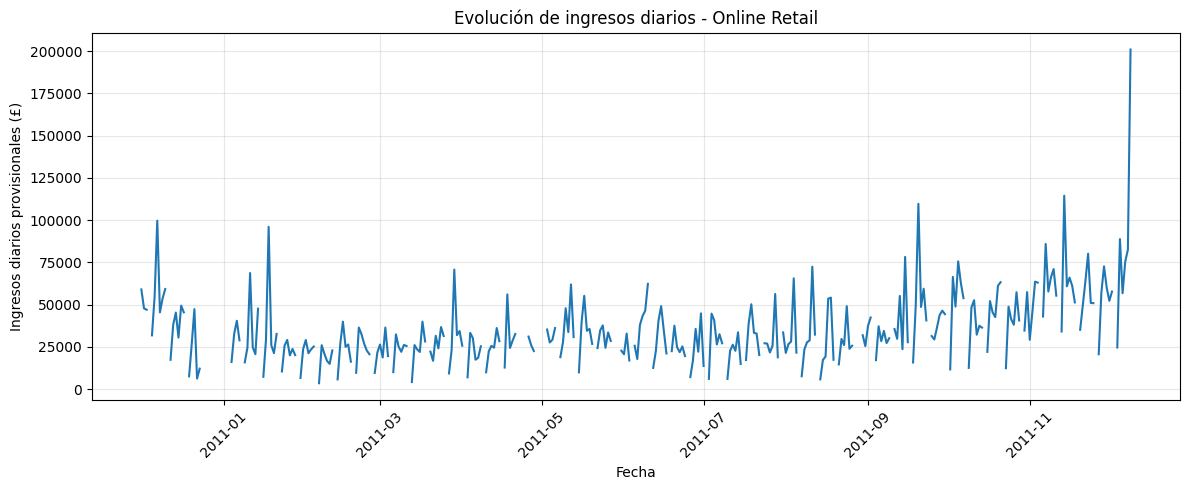

In [ ]:

import matplotlib.pyplot as plt

# Comprobamos que mantenemos los datos originales
print("Filas originales:", len(df))

# Incorporamos todas las fechas del calendario
# Los días sin registros quedan como NaN
serie_calendario = (
    ventas_diarias.set_index("Fecha")["IngresosDiarios"]
    .reindex(calendario)
)

print("Días sin registros:",
      serie_calendario.isna().sum())

# Dibujamos los ingresos diarios
plt.figure(figsize=(12, 5))

plt.plot(
    serie_calendario.index,
    serie_calendario.values
)

plt.title("Evolución de ingresos diarios - Online Retail")
plt.xlabel("Fecha")
plt.ylabel("Ingresos diarios provisionales (£)")
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

# Guardamos el gráfico para el TFM
plt.savefig("evolucion_ingresos_diarios.png", dpi=150)

plt.show()


In [ ]:

# PASO 12: ANALIZAR LOS INGRESOS EXTRAORDINARIOS

# Seleccionamos los diez días con más ingresos
top_dias = ventas_diarias.nlargest(
    10, "IngresosDiarios"
)

print("LOS 10 DÍAS CON MAYORES INGRESOS:")
display(top_dias)

# Identificamos el día con mayores ingresos
fecha_max = top_dias.iloc[0]["Fecha"]

# Seleccionamos sus transacciones
detalle_max = ventas_df[
    ventas_df["Fecha"] == fecha_max
]

print("\nFecha de ingresos máximos:", fecha_max)
print("Número de facturas:", detalle_max["InvoiceNo"].nunique())
print("Número de líneas:", len(detalle_max))

# Mostramos las cinco líneas con mayor importe
print("\nOPERACIONES DE MAYOR IMPORTE:")

display(
    detalle_max.nlargest(5, "IngresoLinea")[
        ["InvoiceNo", "Description",
         "Quantity", "UnitPrice", "IngresoLinea"]
    ]
)


LOS 10 DÍAS CON MAYORES INGRESOS:


,Fecha,IngresosDiarios
304,2011-12-09,200920.60
282,2011-11-14,114419.89
235,2011-09-20,109612.03
5,2010-12-07,99618.20
32,2011-01-18,95978.05
300,2011-12-05,88741.96
276,2011-11-07,85881.81
303,2011-12-08,82495.00
290,2011-11-23,80104.18
231,2011-09-15,78218.95



Fecha de ingresos máximos: 2011-12-09 00:00:00
Número de facturas: 44
Número de líneas: 1625

OPERACIONES DE MAYOR IMPORTE:


,InvoiceNo,Description,Quantity,UnitPrice,IngresoLinea
540421,581483,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.60
541540,581498,DOTCOM POSTAGE,1,1714.17,1714.17
540908,581492,DOTCOM POSTAGE,1,933.17,933.17
540425,581485,ASSORTED COLOUR MINI CASES,84,6.35,533.40
541702,581566,HOME SWEET HOME BLACKBOARD,144,3.26,469.44


In [ ]:

# PASO 13: ANALISIS DE SENSIBILIDAD

# Identificamos la operación extraordinaria
operacion_extrema = (
    (ventas_df["InvoiceNo"].astype(str) == "581483")
    & (ventas_df["StockCode"].astype(str) == "23843")
    & (ventas_df["Quantity"] == 80995)
)

# Revisamos cuántas líneas cumplen la condición
print("Líneas encontradas:", operacion_extrema.sum())

# Calculamos el impacto
importe_extremo = ventas_df.loc[
    operacion_extrema, "IngresoLinea"
].sum()

ingresos_dia = ventas_diarias.loc[
    ventas_diarias["Fecha"] == pd.Timestamp("2011-12-09"),
    "IngresosDiarios"
].iloc[0]

print("Ingresos originales del día:", round(ingresos_dia, 2))
print("Importe operación:", round(importe_extremo, 2))
print("Ingresos sin la operación:",
      round(ingresos_dia - importe_extremo, 2))

print("Porcentaje que representa:",
      round(importe_extremo / ingresos_dia * 100, 2), "%")


Líneas encontradas: 1
Ingresos originales del día: 200920.6
Importe operación: 168469.6
Ingresos sin la operación: 32451.0
Porcentaje que representa: 83.85 %


In [ ]:

# PASO 14: INVESTIGAR POSIBLE DEVOLUCION

# Buscamos el producto de la operación extraordinaria
producto = df[
    df["StockCode"].astype(str) == "23843"
].copy()

# Calculamos el importe con signo
producto["Importe"] = (
    producto["Quantity"] * producto["UnitPrice"]
)

print("OPERACIONES DEL PRODUCTO 23843:")

display(
    producto[
        ["InvoiceNo", "InvoiceDate", "Description",
         "Quantity", "UnitPrice", "Importe"]
    ].sort_values("InvoiceDate")
)

# Buscamos devoluciones por 80.995 unidades
devoluciones = producto[
    producto["Quantity"] == -80995
]

print("\nPOSIBLES DEVOLUCIONES:")
display(devoluciones)

print("\nNÚMERO DE DEVOLUCIONES ENCONTRADAS:",
      len(devoluciones))


OPERACIONES DEL PRODUCTO 23843:


,InvoiceNo,InvoiceDate,Description,Quantity,UnitPrice,Importe
540421,581483,2011-12-09 09:15:00,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.6
540422,C581484,2011-12-09 09:27:00,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.08,-168469.6



POSIBLES DEVOLUCIONES:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Importe
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446.0,United Kingdom,-168469.6



NÚMERO DE DEVOLUCIONES ENCONTRADAS: 1


In [ ]:

# PASO 15: COMPARAR INGRESOS BRUTOS Y NETOS

# Creamos una copia del dataset original
datos_netos = df.copy()

# Excluimos los precios no positivos
# para no mezclar ajustes contables especiales
datos_netos = datos_netos[
    datos_netos["UnitPrice"] > 0
].copy()

# Calculamos importes con signo:
# ventas positivas y cancelaciones negativas
datos_netos["ImporteNeto"] = (
    datos_netos["Quantity"] * datos_netos["UnitPrice"]
)

# Extraemos la fecha
datos_netos["Fecha"] = (
    datos_netos["InvoiceDate"].dt.normalize()
)

# Calculamos los ingresos netos diarios
netos_diarios = (
    datos_netos.groupby("Fecha")["ImporteNeto"]
    .sum()
    .reset_index()
)

# Comparamos con los ingresos brutos
comparacion = ventas_diarias.merge(
    netos_diarios,
    on="Fecha",
    how="outer"
).sort_values("Fecha")

print("COMPARACIÓN DEL 9 DE DICIEMBRE:")

display(
    comparacion[
        comparacion["Fecha"] == "2011-12-09"
    ]
)

print("\nINGRESOS TOTALES:")
print("Brutos:",
      round(ventas_diarias["IngresosDiarios"].sum(), 2))

print("Netos:",
      round(netos_diarios["ImporteNeto"].sum(), 2))


COMPARACIÓN DEL 9 DE DICIEMBRE:


,Fecha,IngresosDiarios,ImporteNeto
304,2011-12-09,200920.6,32131.53



INGRESOS TOTALES:
Brutos: 10666684.54
Netos: 9769872.05


In [ ]:

# PASO 16: ANALISIS DE INGRESOS NETOS DIARIOS

print("Dias con ingresos positivos:",
      (netos_diarios["ImporteNeto"] > 0).sum())

print("Dias con ingresos negativos:",
      (netos_diarios["ImporteNeto"] < 0).sum())

print("Dias con ingresos cero:",
      (netos_diarios["ImporteNeto"] == 0).sum())

print("\nESTADISTICAS DE INGRESOS NETOS:")
display(netos_diarios["ImporteNeto"].describe())

print("\nLOS 5 DIAS CON MENORES INGRESOS NETOS:")
display(netos_diarios.nsmallest(5, "ImporteNeto"))


Dias con ingresos positivos: 304
Dias con ingresos negativos: 1
Dias con ingresos cero: 0

ESTADISTICAS DE INGRESOS NETOS:


,ImporteNeto
count,305.000000
mean,32032.367390
std,17368.713959
min,-1566.230000
25%,20800.720000
50%,28052.620000
75%,42912.400000
max,112141.110000



LOS 5 DIAS CON MENORES INGRESOS NETOS:


,Fecha,ImporteNeto
21,2011-01-05,-1566.23
48,2011-02-06,3457.11
78,2011-03-13,4137.62
204,2011-08-14,5150.18
54,2011-02-13,5535.40


In [ ]:

# PASO 17: INVESTIGAR EL DIA NEGATIVO

fecha_negativa = pd.Timestamp("2011-01-05")

movimientos_dia = datos_netos.loc[
    datos_netos["Fecha"] == fecha_negativa
].copy()

# Separamos importes positivos y negativos
positivos = movimientos_dia.loc[
    movimientos_dia["ImporteNeto"] > 0
]

negativos = movimientos_dia.loc[
    movimientos_dia["ImporteNeto"] < 0
]

print("Facturas distintas:",
      movimientos_dia["InvoiceNo"].nunique())

print("Total de ventas positivas:",
      round(positivos["ImporteNeto"].sum(), 2))

print("Total de movimientos negativos:",
      round(negativos["ImporteNeto"].sum(), 2))

print("Saldo neto del día:",
      round(movimientos_dia["ImporteNeto"].sum(), 2))

print("\nCINCO MOVIMIENTOS NEGATIVOS DE MAYOR IMPORTE:")

display(
    negativos.nsmallest(5, "ImporteNeto")[
        ["InvoiceNo", "Description",
         "Quantity", "UnitPrice", "ImporteNeto"]
    ]
)


Facturas distintas: 72
Total de ventas positivas: 32634.47
Total de movimientos negativos: -34200.7
Saldo neto del día: -1566.23

CINCO MOVIMIENTOS NEGATIVOS DE MAYOR IMPORTE:


,InvoiceNo,Description,Quantity,UnitPrice,ImporteNeto
43702,C540117,AMAZON FEE,-1,16888.02,-16888.02
43703,C540118,AMAZON FEE,-1,16453.71,-16453.71
44152,C540155,OCEAN SCENT CANDLE IN JEWELLED BOX,-54,3.81,-205.74
44302,C540164,CARRIAGE,-1,50.00,-50.00
43783,C540142,JAM MAKING SET WITH JARS,-12,3.75,-45.00


In [ ]:

# PASO 18: INVESTIGAR OPERACIONES ESPECIALES

# Buscamos registros relacionados con Amazon
amazon = df.loc[
    df["Description"]
    .fillna("")
    .astype(str)
    .str.contains("AMAZON FEE", case=False, regex=False, na=False)
].copy()

# Calculamos su importe
amazon["Importe"] = (
    amazon["Quantity"] * amazon["UnitPrice"]
)

print("REGISTROS AMAZON FEE:")
print("Número de registros:", len(amazon))
print("Importe total:", round(amazon["Importe"].sum(), 2))

display(
    amazon[
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "UnitPrice", "Importe"]
    ].head(10)
)

# Identificamos códigos con letras u otros símbolos
codigos_especiales = df.loc[
    ~df["StockCode"]
    .fillna("")
    .astype(str)
    .str.fullmatch(r"\d+", na=False)
]

print("\nCÓDIGOS NO EXCLUSIVAMENTE NUMÉRICOS:")

display(
    codigos_especiales["StockCode"]
    .value_counts().head(20)
)


REGISTROS AMAZON FEE:
Número de registros: 34
Importe total: -221520.5


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,Importe
14514,C537600,AMAZONFEE,AMAZON FEE,-1,1.00,-1.00
15016,C537630,AMAZONFEE,AMAZON FEE,-1,13541.33,-13541.33
15017,537632,AMAZONFEE,AMAZON FEE,1,13541.33,13541.33
16232,C537644,AMAZONFEE,AMAZON FEE,-1,13474.79,-13474.79
16313,C537647,AMAZONFEE,AMAZON FEE,-1,5519.25,-5519.25
16356,C537651,AMAZONFEE,AMAZON FEE,-1,13541.33,-13541.33
16357,C537652,AMAZONFEE,AMAZON FEE,-1,6706.71,-6706.71
43702,C540117,AMAZONFEE,AMAZON FEE,-1,16888.02,-16888.02
43703,C540118,AMAZONFEE,AMAZON FEE,-1,16453.71,-16453.71
96844,C544587,AMAZONFEE,AMAZON FEE,-1,5575.28,-5575.28



CÓDIGOS NO EXCLUSIVAMENTE NUMÉRICOS:


,count
StockCode,
85123A,2313
85099B,2159
POST,1256
85099C,960
82494L,943
85099F,842
DOT,710
M,571
84970S,546


In [ ]:

# PASO 19: PREPARACION DE DATOS COMERCIALES

# Conservamos el dataset original intacto
datos_comerciales = df.copy()

# Identificamos codigos administrativos conocidos
codigos_excluir = [
    "AMAZONFEE",
    "BANK CHARGES",
    "CRUK",
    "D"
]

# Creamos un filtro de operaciones candidatas
filtro = (
    (datos_comerciales["UnitPrice"] > 0)
    & (~datos_comerciales["StockCode"]
       .astype(str).isin(codigos_excluir))
)

# Aplicamos el filtro en una nueva copia
datos_comerciales = datos_comerciales.loc[filtro].copy()

# Calculamos importes conservando el signo
datos_comerciales["ImporteComercial"] = (
    datos_comerciales["Quantity"]
    * datos_comerciales["UnitPrice"]
)

# Extraemos la fecha
datos_comerciales["Fecha"] = (
    datos_comerciales["InvoiceDate"].dt.normalize()
)

# Agrupamos por fecha
ingresos_comerciales = (
    datos_comerciales.groupby("Fecha", as_index=False)
    ["ImporteComercial"]
    .sum()
    .sort_values("Fecha")
)

print("Registros comerciales provisionales:",
      len(datos_comerciales))

print("Ingresos comerciales provisionales:",
      round(datos_comerciales["ImporteComercial"].sum(), 2))

print("Días con registros:",
      len(ingresos_comerciales))

print("\nESTADÍSTICAS:")
display(ingresos_comerciales["ImporteComercial"].describe())

print("\nCINCO DÍAS CON MENORES INGRESOS:")
display(ingresos_comerciales.nsmallest(5, "ImporteComercial"))



Registros comerciales provisionales: 539228
Ingresos comerciales provisionales: 10012197.84
Días con registros: 305

ESTADÍSTICAS:


,ImporteComercial
count,305.000000
mean,32826.878174
std,17933.198763
min,3457.110000
25%,21241.900000
50%,28327.131000
75%,42961.830000
max,113368.860000



CINCO DÍAS CON MENORES INGRESOS:


,Fecha,ImporteComercial
48,2011-02-06,3457.11
78,2011-03-13,4137.62
54,2011-02-13,5535.40
204,2011-08-14,5584.69
174,2011-07-10,5692.07


In [ ]:

# PASO 20: AUDITORIA FINAL DE EXCLUSIONES

codigos_excluir = [
    "AMAZONFEE", "BANK CHARGES", "CRUK", "D"
]

# Seleccionamos los códigos excluidos
revision = df.loc[
    df["StockCode"].astype(str).isin(codigos_excluir)
].copy()

revision["Importe"] = (
    revision["Quantity"] * revision["UnitPrice"]
)

resumen = (
    revision.groupby(
        ["StockCode", "Description"],
        dropna=False
    )
    .agg(
        Registros=("InvoiceNo", "size"),
        Importe=("Importe", "sum")
    )
    .reset_index()
    .sort_values("Registros", ascending=False)
)

print("CONCEPTOS EXCLUIDOS:")
display(resumen)

print("\nTOTAL EXCLUIDO POR ESTOS CÓDIGOS:")
print(round(revision["Importe"].sum(), 2))

print("\nFECHA FINAL DEL DATASET:")
print(df["InvoiceDate"].max())



CONCEPTOS EXCLUIDOS:


,StockCode,Description,Registros,Importe
3,D,Discount,77,-5696.220
1,BANK CHARGES,Bank Charges,37,-7175.639
0,AMAZONFEE,AMAZON FEE,34,-221520.500
2,CRUK,CRUK Commission,16,-7933.430



TOTAL EXCLUIDO POR ESTOS CÓDIGOS:
-242325.79

FECHA FINAL DEL DATASET:
2011-12-09 12:50:00


In [ ]:

# PASO 21: CREAR DATASET COMERCIAL

# Códigos de gastos administrativos
codigos_gastos = [
    "AMAZONFEE",
    "BANK CHARGES",
    "CRUK"
]

# Creamos copia de los datos originales
datos_finales = df.copy()

# Filtramos únicamente gastos conocidos
# y registros sin precio positivo
filtro = (
    (datos_finales["UnitPrice"] > 0)
    & (~datos_finales["StockCode"]
       .astype(str).isin(codigos_gastos))
)

datos_finales = datos_finales.loc[filtro].copy()

# Calculamos ingresos comerciales con signo
datos_finales["IngresoComercial"] = (
    datos_finales["Quantity"]
    * datos_finales["UnitPrice"]
)

# Extraemos la fecha
datos_finales["Fecha"] = (
    datos_finales["InvoiceDate"].dt.normalize()
)

# Agrupamos ingresos por día
serie_final = (
    datos_finales.groupby("Fecha", as_index=False)
    ["IngresoComercial"]
    .sum()
    .sort_values("Fecha")
)

print("Registros seleccionados:", len(datos_finales))

print("Ingresos comerciales:",
      round(datos_finales["IngresoComercial"].sum(), 2))

print("Días disponibles:", len(serie_final))

print("\nESTADÍSTICAS:")
display(serie_final["IngresoComercial"].describe())

print("\nPRIMEROS REGISTROS:")
display(serie_final.head())


Registros seleccionados: 539305
Ingresos comerciales: 10006501.62
Días disponibles: 305

ESTADÍSTICAS:


,IngresoComercial
count,305.000000
mean,32808.202043
std,17930.357088
min,3457.110000
25%,21241.900000
50%,28327.131000
75%,42940.910000
max,113179.860000



PRIMEROS REGISTROS:


,Fecha,IngresoComercial
0,2010-12-01,58635.56
1,2010-12-02,46192.28
2,2010-12-03,45620.46
3,2010-12-05,31383.95
4,2010-12-06,53860.18


In [ ]:

# PASO 22: PREPARAR LA SERIE TEMPORAL

# Creamos una copia para no modificar serie_final
serie_modelo = serie_final.copy()

# Nos aseguramos de que las fechas sean correctas
serie_modelo["Fecha"] = pd.to_datetime(
    serie_modelo["Fecha"]
)

# Ordenamos cronológicamente
serie_modelo = serie_modelo.sort_values(
    "Fecha"
).reset_index(drop=True)

# Excluimos provisionalmente el último día
ultima_fecha = serie_modelo["Fecha"].max()

serie_modelo = serie_modelo.loc[
    serie_modelo["Fecha"] < ultima_fecha
].copy()

# Comprobamos el resultado
print("Última fecha excluida:", ultima_fecha)

print("Días disponibles para modelado:",
      len(serie_modelo))

print("Primera fecha:",
      serie_modelo["Fecha"].min())

print("Última fecha utilizada:",
      serie_modelo["Fecha"].max())

print("\nÚLTIMOS CINCO REGISTROS:")
display(serie_modelo.tail())

print("\nVALORES AUSENTES:")
print(serie_modelo.isna().sum())


Última fecha excluida: 2011-12-09 00:00:00
Días disponibles para modelado: 304
Primera fecha: 2010-12-01 00:00:00
Última fecha utilizada: 2011-12-08 00:00:00

ÚLTIMOS CINCO REGISTROS:


,Fecha,IngresoComercial
299,2011-12-04,24565.78
300,2011-12-05,88274.72
301,2011-12-06,54228.37
302,2011-12-07,75061.22
303,2011-12-08,81417.78



VALORES AUSENTES:
Fecha               0
IngresoComercial    0
dtype: int64


In [ ]:

# PASO 23: PREPARAR VARIABLES PARA MACHINE LEARNING

import pandas as pd
import numpy as np

# Partimos de la serie preparada en el paso 22
modelo_df = serie_modelo.copy()

# Ordenamos los registros
modelo_df = modelo_df.sort_values(
    "Fecha"
).reset_index(drop=True)

# Variable objetivo: ingresos del día observado
modelo_df["Objetivo"] = modelo_df["IngresoComercial"]

# Variables de calendario
modelo_df["DiaSemana"] = modelo_df["Fecha"].dt.dayofweek
modelo_df["Mes"] = modelo_df["Fecha"].dt.month

# Ingresos de días anteriores con actividad registrada
modelo_df["IngresoAnterior1"] = modelo_df["Objetivo"].shift(1)
modelo_df["IngresoAnterior2"] = modelo_df["Objetivo"].shift(2)
modelo_df["IngresoAnterior7"] = modelo_df["Objetivo"].shift(7)

# Media de las 7 observaciones anteriores
modelo_df["MediaAnterior7"] = (
    modelo_df["Objetivo"]
    .shift(1)
    .rolling(window=7)
    .mean()
)

# Eliminamos únicamente las primeras filas sin histórico
modelo_df = modelo_df.dropna().reset_index(drop=True)

# Verificamos el resultado
print("FILAS DISPONIBLES:", len(modelo_df))

print("\nVALORES AUSENTES:")
print(modelo_df.isna().sum())

print("\nPRIMEROS REGISTROS:")
display(modelo_df.head())


FILAS DISPONIBLES: 297

VALORES AUSENTES:
Fecha               0
IngresoComercial    0
Objetivo            0
DiaSemana           0
Mes                 0
IngresoAnterior1    0
IngresoAnterior2    0
IngresoAnterior7    0
MediaAnterior7      0
dtype: int64

PRIMEROS REGISTROS:


,Fecha,IngresoComercial,Objetivo,DiaSemana,Mes,IngresoAnterior1,IngresoAnterior2,IngresoAnterior7,MediaAnterior7
0,2010-12-09,52532.13,52532.13,3,12,44189.84,84397.51,58635.56,52039.968571
1,2010-12-10,57404.91,57404.91,4,12,52532.13,44189.84,46192.28,51168.050000
2,2010-12-12,17240.92,17240.92,6,12,57404.91,52532.13,45620.46,52769.854286
3,2010-12-13,36346.26,36346.26,0,12,17240.92,57404.91,31383.95,48715.634286
4,2010-12-14,42843.29,42843.29,1,12,36346.26,17240.92,53860.18,49424.535714


In [ ]:

# PASO 24: DIVISION CRONOLOGICA

# Variables predictoras
variables = [
    "DiaSemana",
    "Mes",
    "IngresoAnterior1",
    "IngresoAnterior2",
    "IngresoAnterior7",
    "MediaAnterior7"
]

X = modelo_df[variables]
y = modelo_df["Objetivo"]

# Dividimos cronológicamente: 70 % / 15 % / 15 %
n = len(modelo_df)
fin_train = int(n * 0.70)
fin_val = int(n * 0.85)

X_train = X.iloc[:fin_train]
X_val = X.iloc[fin_train:fin_val]
X_test = X.iloc[fin_val:]

y_train = y.iloc[:fin_train]
y_val = y.iloc[fin_train:fin_val]
y_test = y.iloc[fin_val:]

print("ENTRENAMIENTO:", len(X_train), "observaciones")
print("VALIDACIÓN:", len(X_val), "observaciones")
print("PRUEBA:", len(X_test), "observaciones")

print("\nFECHAS DE CADA BLOQUE:")

for nombre, indices in [
    ("Train", X_train.index),
    ("Validación", X_val.index),
    ("Test", X_test.index)
]:
    print(
        nombre,
        modelo_df.loc[indices, "Fecha"].min(),
        "hasta",
        modelo_df.loc[indices, "Fecha"].max()
    )


ENTRENAMIENTO: 207 observaciones
VALIDACIÓN: 45 observaciones
PRUEBA: 45 observaciones

FECHAS DE CADA BLOQUE:
Train 2010-12-09 00:00:00 hasta 2011-08-24 00:00:00
Validación 2011-08-25 00:00:00 hasta 2011-10-17 00:00:00
Test 2011-10-18 00:00:00 hasta 2011-12-08 00:00:00


In [ ]:

# PASO 25: MODELOS DE REFERENCIA

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
import numpy as np
import pandas as pd

# Predicciones usando únicamente información anterior
pred_anterior = X_val["IngresoAnterior1"]
pred_media7 = X_val["MediaAnterior7"]

# Función para evaluar los modelos
def evaluar_modelo(nombre, reales, predicciones):
    mae = mean_absolute_error(reales, predicciones)
    rmse = np.sqrt(
        mean_squared_error(reales, predicciones)
    )

    return {
        "Modelo": nombre,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2)
    }

# Comparación
resultados_base = pd.DataFrame([
    evaluar_modelo(
        "Última jornada",
        y_val,
        pred_anterior
    ),
    evaluar_modelo(
        "Media de 7 jornadas",
        y_val,
        pred_media7
    )
])

print("RESULTADOS DE VALIDACIÓN:")
display(resultados_base)

print("\nMEJOR MODELO SEGÚN MAE:")
display(resultados_base.nsmallest(1, "MAE"))


RESULTADOS DE VALIDACIÓN:


,Modelo,MAE,RMSE
0,Última jornada,19191.79,25526.91
1,Media de 7 jornadas,13807.43,18918.57



MEJOR MODELO SEGÚN MAE:


,Modelo,MAE,RMSE
1,Media de 7 jornadas,13807.43,18918.57


In [ ]:

# PASO 26: ENTRENAR Y COMPARAR MODELOS

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

# Modelo 1: Regresión lineal
modelo_lineal = LinearRegression()
modelo_lineal.fit(X_train, y_train)

# Modelo 2: Random Forest
modelo_rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=5,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

modelo_rf.fit(X_train, y_train)

# Predicciones de validación
pred_lineal = modelo_lineal.predict(X_val)
pred_rf = modelo_rf.predict(X_val)

# Evaluación de los dos modelos
resultados_ml = pd.DataFrame([
    evaluar_modelo(
        "Regresión lineal", y_val, pred_lineal
    ),
    evaluar_modelo(
        "Random Forest", y_val, pred_rf
    )
])

# Comparación con los modelos de referencia
comparacion_modelos = pd.concat(
    [resultados_base, resultados_ml],
    ignore_index=True
).sort_values("MAE")

print("COMPARACIÓN DE LOS CUATRO MODELOS:")
display(comparacion_modelos)

print("\nMEJOR MODELO SEGÚN MAE:")
display(comparacion_modelos.head(1))


COMPARACIÓN DE LOS CUATRO MODELOS:


,Modelo,MAE,RMSE
3,Random Forest,11622.47,17537.00
2,Regresión lineal,13011.27,18102.27
1,Media de 7 jornadas,13807.43,18918.57
0,Última jornada,19191.79,25526.91



MEJOR MODELO SEGÚN MAE:


,Modelo,MAE,RMSE
3,Random Forest,11622.47,17537.0


In [ ]:

# PASO 27: RED NEURONAL MLP

from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Construimos una red neuronal pequeña
modelo_mlp = Pipeline([
    ("escalado", StandardScaler()),
    ("red_neuronal", MLPRegressor(
        hidden_layer_sizes=(16, 8),
        activation="relu",
        solver="adam",
        alpha=10.0,
        learning_rate_init=0.001,
        max_iter=2000,
        early_stopping=False,
        random_state=42
    ))
])

# Entrenamos usando únicamente entrenamiento
modelo_mlp.fit(X_train, y_train)

# Predecimos sobre validación
pred_mlp = modelo_mlp.predict(X_val)

# Evaluamos
resultado_mlp = evaluar_modelo(
    "Red neuronal MLP",
    y_val,
    pred_mlp
)

print("RESULTADO DE LA RED NEURONAL:")
display(pd.DataFrame([resultado_mlp]))

# Comparamos con los cuatro modelos anteriores
comparacion_completa = pd.concat(
    [
        comparacion_modelos,
        pd.DataFrame([resultado_mlp])
    ],
    ignore_index=True
).sort_values("MAE").reset_index(drop=True)

print("\nCOMPARACIÓN DE LOS CINCO MODELOS:")
display(comparacion_completa)

# Comprobamos si el entrenamiento convergió
red = modelo_mlp.named_steps["red_neuronal"]

print("\nIteraciones utilizadas:", red.n_iter_)
print("Pérdida final de entrenamiento:", red.loss_)


RESULTADO DE LA RED NEURONAL:


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (2000) reached and the optimization hasn't converged yet.
  warnings.warn(


,Modelo,MAE,RMSE
0,Red neuronal MLP,16924.73,23965.48



COMPARACIÓN DE LOS CINCO MODELOS:


,Modelo,MAE,RMSE
0,Random Forest,11622.47,17537.00
1,Regresión lineal,13011.27,18102.27
2,Media de 7 jornadas,13807.43,18918.57
3,Red neuronal MLP,16924.73,23965.48
4,Última jornada,19191.79,25526.91



Iteraciones utilizadas: 2000
Pérdida final de entrenamiento: 137383290.12213206


IMPORTANCIA INTERNA DE RANDOM FOREST:


,Variable,Importancia
0,DiaSemana,0.442252
5,MediaAnterior7,0.148877
4,IngresoAnterior7,0.141278
3,IngresoAnterior2,0.114799
2,IngresoAnterior1,0.077609
1,Mes,0.075185



IMPORTANCIA POR PERMUTACIÓN:


,Variable,AumentoMAE,Desviacion
0,DiaSemana,3.874181e+03,6.667000e+02
5,MediaAnterior7,9.871581e+02,5.529572e+02
4,IngresoAnterior7,2.056720e+01,1.902714e+02
1,Mes,-5.456968e-13,8.335657e-13
3,IngresoAnterior2,-9.192118e+01,2.705941e+02
2,IngresoAnterior1,-1.969931e+02,1.143205e+02


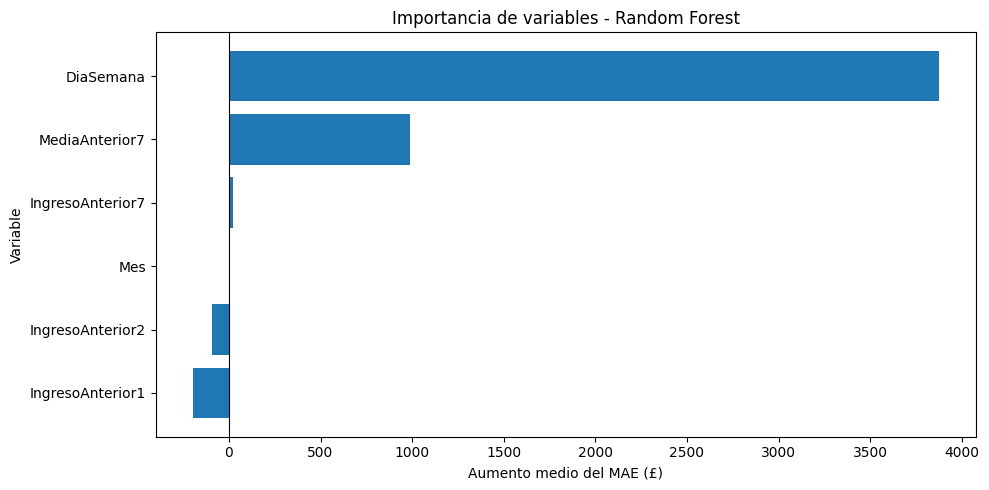

In [ ]:

# PASO 28: EXPLICABILIDAD DE RANDOM FOREST

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

# 1. Importancia interna del modelo
importancia_interna = pd.DataFrame({
    "Variable": X_train.columns,
    "Importancia": modelo_rf.feature_importances_
}).sort_values("Importancia", ascending=False)

print("IMPORTANCIA INTERNA DE RANDOM FOREST:")
display(importancia_interna)

# 2. Importancia por permutación
# Utilizamos VALIDACIÓN, no el conjunto de prueba
resultado_perm = permutation_importance(
    modelo_rf,
    X_val,
    y_val,
    scoring="neg_mean_absolute_error",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

importancia_permutacion = pd.DataFrame({
    "Variable": X_val.columns,
    "AumentoMAE": resultado_perm.importances_mean,
    "Desviacion": resultado_perm.importances_std
}).sort_values("AumentoMAE", ascending=False)

print("\nIMPORTANCIA POR PERMUTACIÓN:")
display(importancia_permutacion)

# 3. Gráfico de importancia por permutación
plt.figure(figsize=(10, 5))

plt.barh(
    importancia_permutacion["Variable"],
    importancia_permutacion["AumentoMAE"]
)

plt.xlabel("Aumento medio del MAE (£)")
plt.ylabel("Variable")
plt.title("Importancia de variables - Random Forest")

plt.axvline(0, color="black", linewidth=0.8)
plt.gca().invert_yaxis()
plt.tight_layout()

plt.savefig(
    "importancia_variables_random_forest.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


PREDICCIONES ANALIZADAS:


,DiaSemana,Mes,IngresoAnterior1,IngresoAnterior2,IngresoAnterior7,MediaAnterior7
207,3,8,48265.06,25756.30,50004.68,33861.124286
208,4,8,22620.34,48265.06,53225.67,29949.075714
209,6,8,25550.23,22620.34,17248.54,25995.441429
210,1,8,10784.78,25550.23,14549.21,25072.047143
211,2,8,31642.50,10784.78,27978.41,27513.945714


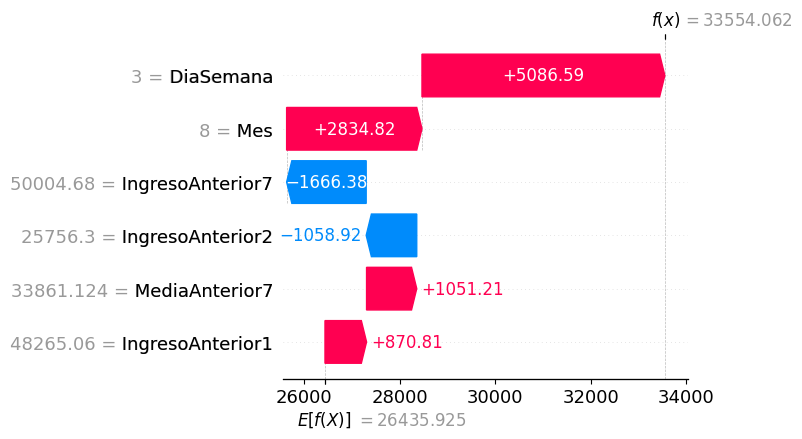

In [ ]:

# PASO 29: EXPLICABILIDAD LOCAL CON SHAP

import shap
import pandas as pd
import matplotlib.pyplot as plt

# Creamos el explicador de Random Forest
explainer = shap.TreeExplainer(modelo_rf)

# Seleccionamos cinco observaciones de validación
X_ejemplos = X_val.iloc[:5].copy()

# Calculamos las contribuciones SHAP
valores_shap = explainer(X_ejemplos)

# Mostramos las variables y sus contribuciones
print("PREDICCIONES ANALIZADAS:")
display(X_ejemplos)

# Explicamos la primera predicción
shap.plots.waterfall(
    valores_shap[0],
    max_display=10,
    show=False
)

plt.tight_layout()
plt.savefig(
    "shap_prediccion_individual.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()


In [ ]:

# PASO 30: EVALUACION FINAL EN TEST

import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Predicciones con modelos ya seleccionados
# No reentrenamos ni modificamos hiperparámetros
pred_test_rf = modelo_rf.predict(X_test)

# Referencia: media de las 7 jornadas anteriores
pred_test_base = X_test["MediaAnterior7"].to_numpy()

# Calcular métricas
def metricas_test(nombre, pred):
    return {
        "Modelo": nombre,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred))
    }

resultados_test = pd.DataFrame([
    metricas_test("Media de 7 jornadas", pred_test_base),
    metricas_test("Random Forest", pred_test_rf)
])

print("RESULTADOS FINALES EN TEST:")
display(resultados_test.round(2))

# Mejora respecto al modelo de referencia
mae_base = resultados_test.iloc[0]["MAE"]
mae_rf = resultados_test.iloc[1]["MAE"]

mejora = (mae_base - mae_rf) / mae_base * 100

print(f"\nMejora del MAE: {mejora:.2f}%")

# Guardar resultados para GitHub
resultados_test.to_csv(
    "resultados_evaluacion_final.csv",
    index=False
)


RESULTADOS FINALES EN TEST:


,Modelo,MAE,RMSE
0,Media de 7 jornadas,14015.88,18744.80
1,Random Forest,18924.47,23767.55



Mejora del MAE: -35.02%


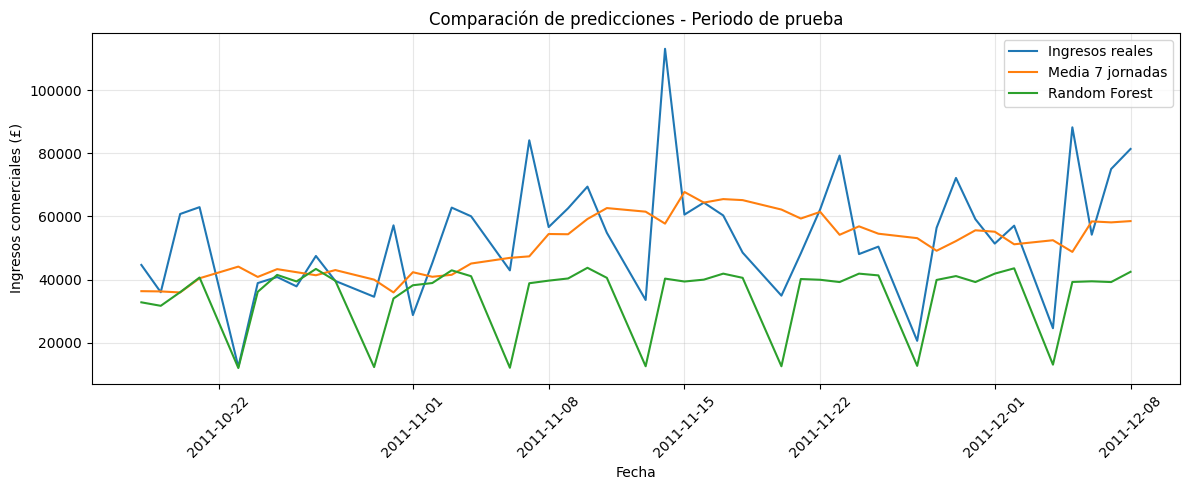

CINCO MAYORES ERRORES DE RANDOM FOREST:


,Fecha,Real,Media7,RandomForest,ErrorMedia7,ErrorRF
23,2011-11-14,113179.86,57736.21,40300.55,55443.65,72879.31
41,2011-12-05,88274.72,48774.09,39240.20,39500.63,49034.52
17,2011-11-07,84164.48,47359.38,38830.54,36805.10,45333.94
31,2011-11-23,79330.63,54199.08,39209.76,25131.55,40120.87
44,2011-12-08,81417.78,58539.73,42459.87,22878.05,38957.91


In [ ]:

# PASO 31: ANALISIS FINAL DE PREDICCIONES

import pandas as pd
import matplotlib.pyplot as plt

# Fechas correspondientes al conjunto de prueba
fechas_test = modelo_df.loc[X_test.index, "Fecha"]

# Construimos una tabla de comparación
analisis_test = pd.DataFrame({
    "Fecha": fechas_test.to_numpy(),
    "Real": y_test.to_numpy(),
    "Media7": pred_test_base,
    "RandomForest": pred_test_rf
})

# Calculamos errores absolutos
analisis_test["ErrorMedia7"] = abs(
    analisis_test["Real"] - analisis_test["Media7"]
)

analisis_test["ErrorRF"] = abs(
    analisis_test["Real"] - analisis_test["RandomForest"]
)

# Visualizamos las predicciones
plt.figure(figsize=(12, 5))

plt.plot(analisis_test["Fecha"],
         analisis_test["Real"],
         label="Ingresos reales")

plt.plot(analisis_test["Fecha"],
         analisis_test["Media7"],
         label="Media 7 jornadas")

plt.plot(analisis_test["Fecha"],
         analisis_test["RandomForest"],
         label="Random Forest")

plt.title("Comparación de predicciones - Periodo de prueba")
plt.xlabel("Fecha")
plt.ylabel("Ingresos comerciales (£)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("comparacion_predicciones_test.png", dpi=150)
plt.show()

# Días con los mayores errores de Random Forest
print("CINCO MAYORES ERRORES DE RANDOM FOREST:")
display(
    analisis_test.nlargest(5, "ErrorRF").round(2)
)

# Guardamos resultados reproducibles
analisis_test.to_csv(
    "predicciones_test.csv",
    index=False
)


In [ ]:

# PASO 32: METRICAS DE NEGOCIO

import numpy as np
import pandas as pd

# Utilizamos los resultados del paso 31
negocio = analisis_test.copy()

# Calculamos diferencias entre ingresos reales y predicciones
for modelo in ["Media7", "RandomForest"]:

    diferencia = negocio["Real"] - negocio[modelo]

    negocio[f"Subestimacion_{modelo}"] = (
        diferencia.clip(lower=0)
    )

    negocio[f"Sobreestimacion_{modelo}"] = (
        (-diferencia).clip(lower=0)
    )

# Resumimos los indicadores
resumen_negocio = []

for modelo in ["Media7", "RandomForest"]:

    subestimacion = negocio[f"Subestimacion_{modelo}"]
    sobreestimacion = negocio[f"Sobreestimacion_{modelo}"]

    resumen_negocio.append({
        "Modelo": modelo,
        "Subestimacion_total": round(subestimacion.sum(), 2),
        "Sobreestimacion_total": round(sobreestimacion.sum(), 2),
        "Dias_subestimados": int((subestimacion > 0).sum()),
        "Tasa_subestimacion_%": round(
            (subestimacion > 0).mean() * 100, 2
        )
    })

resumen_negocio = pd.DataFrame(resumen_negocio)

print("INDICADORES EMPRESARIALES:")
display(resumen_negocio)

print("\nNUMERO DE DIAS EVALUADOS:", len(negocio))


INDICADORES EMPRESARIALES:


,Modelo,Subestimacion_total,Sobreestimacion_total,Dias_subestimados,Tasa_subestimacion_%
0,Media7,378730.16,251984.62,23,51.11
1,RandomForest,839841.56,11759.59,41,91.11



NUMERO DE DIAS EVALUADOS: 45


In [ ]:

# PASO 34: EXPORTAR DATOS PARA EL DASHBOARD

from pathlib import Path
import pandas as pd

# Creamos una carpeta para los resultados
carpeta = Path("dashboard_tfm")
carpeta.mkdir(exist_ok=True)

# 1. Ingresos comerciales históricos
historico = serie_final[
    ["Fecha", "IngresoComercial"]
].copy()

historico.to_csv(
    carpeta / "ingresos_historicos.csv",
    index=False
)

# 2. Predicciones del conjunto de prueba
predicciones = analisis_test[
    ["Fecha", "Real", "Media7", "RandomForest",
     "ErrorMedia7", "ErrorRF"]
].copy()

predicciones.to_csv(
    carpeta / "predicciones_test.csv",
    index=False
)

# Verificamos los archivos creados
for archivo in carpeta.glob("*.csv"):
    print(
        archivo.name,
        "-",
        round(archivo.stat().st_size / 1024, 2),
        "KB"
    )

print("\nFILAS EXPORTADAS:")
print("Histórico:", len(historico))
print("Predicciones:", len(predicciones))

print("\nPRIMERAS PREDICCIONES:")
display(predicciones.head())


predicciones_test.csv - 4.1 KB
ingresos_historicos.csv - 6.09 KB

FILAS EXPORTADAS:
Histórico: 305
Predicciones: 45

PRIMERAS PREDICCIONES:


,Fecha,Real,Media7,RandomForest,ErrorMedia7,ErrorRF
0,2011-10-18,44637.84,36318.442857,32780.587885,8319.397143,11857.252115
1,2011-10-19,35988.43,36238.101429,31675.565029,249.671429,4312.864971
2,2011-10-20,60793.14,35912.484286,35995.968519,24880.655714,24797.171481
3,2011-10-21,62961.26,40411.097143,40647.784341,22550.162857,22313.475659
4,2011-10-23,12302.41,44110.252857,11945.919854,31807.842857,356.490146


In [ ]:

# PASO 35: DESCARGAR ARCHIVOS PARA TABLEAU

from google.colab import files

files.download(
    "dashboard_tfm/ingresos_historicos.csv"
)

files.download(
    "dashboard_tfm/predicciones_test.csv"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# Exportar CSV compatible con configuración española

historico.to_csv(
    "ingresos_tableau.csv",
    index=False,
    sep=";",
    decimal=",",
    encoding="utf-8-sig"
)

from google.colab import files
files.download("ingresos_tableau.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# PASO 38: EXPORTAR PREDICCIONES PARA TABLEAU

import pandas as pd
from google.colab import files

# Recuperamos el CSV del paso 34
predicciones = pd.read_csv(
    "dashboard_tfm/predicciones_test.csv"
)

# Exportamos en formato compatible con Tableau
predicciones.to_csv(
    "predicciones_tableau.csv",
    index=False,
    sep=";",
    decimal=",",
    encoding="utf-8-sig"
)

# Verificamos los datos
print("Número de registros:", len(predicciones))
print("Columnas:", predicciones.columns.tolist())

display(predicciones.head())

# Descargamos el CSV
files.download("predicciones_tableau.csv")


Número de registros: 45
Columnas: ['Fecha', 'Real', 'Media7', 'RandomForest', 'ErrorMedia7', 'ErrorRF']


,Fecha,Real,Media7,RandomForest,ErrorMedia7,ErrorRF
0,2011-10-18,44637.84,36318.442857,32780.587885,8319.397143,11857.252115
1,2011-10-19,35988.43,36238.101429,31675.565029,249.671429,4312.864971
2,2011-10-20,60793.14,35912.484286,35995.968519,24880.655714,24797.171481
3,2011-10-21,62961.26,40411.097143,40647.784341,22550.162857,22313.475659
4,2011-10-23,12302.41,44110.252857,11945.919854,31807.842857,356.490146


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>